<a href="https://colab.research.google.com/github/x-nbriones/Briones-CS3B_CSST102/blob/main/CSST102_Exer3(Task1).ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Machine Learning | Natural Language Processing | Naive Bayes Classification

**Task 1 — Dataset Exploration and Analysis**

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

*Display the first 10 records and dataset dimensions.*

In [17]:
df = pd.read_csv('spam.csv')

print("First 10 records:")
df.head(10)

First 10 records:


,v1,v2,Unnamed: 2,Unnamed: 3,Unnamed: 4
0,ham,"Go until jurong point, crazy.. Available only ...",NaN,NaN,NaN
1,ham,Ok lar... Joking wif u oni...,NaN,NaN,NaN
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...,NaN,NaN,NaN
3,ham,U dun say so early hor... U c already then say...,NaN,NaN,NaN
4,ham,"Nah I don't think he goes to usf, he lives aro...",NaN,NaN,NaN
5,spam,FreeMsg Hey there darling it's been 3 week's n...,NaN,NaN,NaN
6,ham,Even my brother is not like to speak with me. ...,NaN,NaN,NaN
7,ham,As per your request 'Melle Melle (Oru Minnamin...,NaN,NaN,NaN
8,spam,WINNER!! As a valued network customer you have...,NaN,NaN,NaN
9,spam,Had your mobile 11 months or more? U R entitle...,NaN,NaN,NaN


In [18]:
print("Dataset Dimension:")
df.shape

Dataset Dimension:


(5572, 5)

*Identify missing values and duplicate messages.*

In [16]:
print("Missing values:")
df.isnull().sum()

Missing values:


,0
v1,0
v2,0
Unnamed: 2,5522
Unnamed: 3,5560
Unnamed: 4,5566


In [15]:
print("Duplicate messages:")
df.duplicated().sum()

Duplicate messages:


np.int64(403)

*Remove unccessary columns and renmae v1 to class adn v2 to message*

In [19]:
df_clean = df[['v1', 'v2']].copy()

In [20]:
df_clean.rename(columns={'v1': 'class',
                         'v2': 'message'}, inplace=True)

df_clean.head()

,class,message
0,ham,"Go until jurong point, crazy.. Available only ..."
1,ham,Ok lar... Joking wif u oni...
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...
3,ham,U dun say so early hor... U c already then say...
4,ham,"Nah I don't think he goes to usf, he lives aro..."


*Display the number and percentage of spam and ham messages.*

In [21]:
counts = df_clean['class'].value_counts()
percentages = df_clean['class'].value_counts(normalize=True) * 100

In [23]:
summary_df = pd.DataFrame({
    'Count': counts,
    'Percentage': percentages.round(2)
})

summary_df

,Count,Percentage
class,,
ham,4825,86.59
spam,747,13.41


*Create a bar chart showing the class distribution.*

In [24]:
class_counts = df_clean['class'].value_counts()

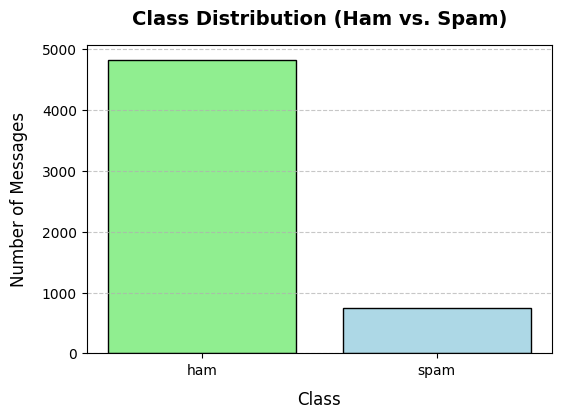

In [33]:
plt.figure(figsize=(6, 4))
bars = plt.bar(class_counts.index, class_counts.values,
               color=['lightgreen', 'lightblue'], edgecolor='black')

plt.title('Class Distribution (Ham vs. Spam)',
          fontsize=14, fontweight='bold', pad=15)
plt.xlabel('Class', fontsize=12, labelpad=10)
plt.ylabel('Number of Messages', fontsize=12, labelpad=10)
plt.grid(axis='y', linestyle='--', alpha=0.7)

*Explain whether the dataset is balanced or imbalanced.*

The dataset is imbalanced. As shown in numbers and percentages between ham and spam, there's a big disproportion between the two. Ham messages account for 4825 approximately 86.59%, whereas spam messages only have 747 or 13.41%. This gives us an imbalanced dataset